# 1ª entrega — Análise Exploratória de Dados (AED) comentada

**Nome:** Gabriela Marino Koerich · **Disciplina:** Python Machine Learning

**Pergunta do projeto:** a partir de biomarcadores, é possível (1) classificar o paciente em `BCG`, `cancer`, `imunodeficiencia` ou `leucemia`, (2) prever o valor de `IFN-γ` e (3) encontrar grupos naturais (clusters)?

**Critérios de sucesso** (definidos antes do treinamento,conforme aula 03 — Objetivos; os valores mínimos são escolhas deste projeto):

| Tarefa | Métrica principal | Meta | Justificativa |
|---|---|---|---|
| Classificação | F1-macro (média do F1 das 4 classes) | ≥ 0,75 | Com 4 classes balanceadas, o acaso acerta ~25%; a meta exige desempenho três vezes maior. O F1-macro dá o mesmo peso às 4 classes e combina precisão e recall. |
| Regressão (IFN-γ) | R² | ≥ 0,70 | O modelo deve explicar pelo menos 70% da variabilidade do IFN-γ. MAE e RMSE são relatados na unidade da variável. |
| Clusterização | Silhueta | ≥ 0,50 | Na escala de Kaufman & Rousseeuw (1990), silhueta acima de 0,50 indica estrutura de grupos razoável. O ARI compara os grupos com as classes reais. |

**Critério adicional:** nos testes de hipótese (qui-quadrado, Kolmogorov-Smirnov, t, Mann-Whitney e Levene), adota-se α = 0,05; p > 0,05 indica que não há diferença estatística entre as distribuições comparadas.

**Quem toma a decisão:** em um contexto de triagem clínica, deixar de identificar um paciente doente (falso negativo) é mais grave que um alarme falso; por isso, além do F1, o recall de cada classe deve ser acompanhado no classification report.

**Testes de hipótese utilizados**

**Critério adicional — testes de hipótese (α = 0,05):** p > 0,05 → não se rejeita H0 (não há diferença estatística); p ≤ 0,05 → rejeita-se H0.

| Etapa | Teste | O que é comparado | H0 (hipótese nula) | Onde aparece |
|---|---|---|---|---|
| AED | Qui-quadrado de aderência | Frequência das 4 classes | As classes têm a mesma frequência (25% cada) | Seção 3 (balanceamento) e seção 9.3 |
| AED | Kruskal-Wallis | Cada biomarcador entre as 4 classes | O biomarcador tem a mesma distribuição nas 4 classes | Seção 5 (e bloco correlacionado, seção 6) |
| AED | Qui-quadrado de independência | FOXP3 × classe | FOXP3 e classe são independentes | Seção 5 |
| Classificação | Qui-quadrado de homogeneidade | Classes **previstas** no treino × no teste | A distribuição das classes previstas é igual no treino e no teste | App, painel de cada modelo |
| Classificação | Qui-quadrado | Classes **previstas** × **observadas** no teste | A distribuição prevista é igual à observada | App, tabela comparativa no topo da aba |
| Regressão | Kolmogorov-Smirnov | Previsões de IFN-γ no treino × no teste | As duas amostras têm a mesma distribuição | App, painel de cada modelo |
| Regressão | Teste t | Previsões no treino × no teste | As médias são iguais | App, painel de cada modelo |
| Regressão | Mann-Whitney | Previsões no treino × no teste | As medianas (distribuições) são iguais | App, painel de cada modelo |
| Regressão | Levene | Previsões no treino × no teste | As variâncias são iguais | App, painel de cada modelo |
| Regressão | Mann-Whitney | IFN-γ **previsto** × **observado** no teste | Previsto e observado têm a mesma distribuição | App, tabela comparativa no topo da aba |
| Clusterização | Qui-quadrado de aderência | Proporção dos grupos na validação × no treino | A distribuição dos grupos na validação é igual à do treino | App, painel de cada algoritmo |
| Clusterização | Qui-quadrado de aderência | Proporção dos grupos no teste × no treino | A distribuição dos grupos no teste é igual à do treino | App, tabela comparativa no topo da aba |

Além dos testes, a clusterização usa o **ARI** (Adjusted Rand Index), que não é um teste de hipótese, mas uma medida de concordância: compara os grupos do modelo do treino com os de um modelo ajustado só na validação (ARI ≥ 0,5 = semelhantes) e os grupos com as classes reais.

In [3]:
# Garante que o notebook rode a partir da pasta notebooks/ do projeto.
# No container, o projeto fica em /app (a pasta meu_projeto_ml espelhada).
import os

if os.path.isdir("/app/notebooks"):
    os.chdir("/app/notebooks")
print("Pasta de trabalho:", os.getcwd())

Pasta de trabalho: /app/notebooks


In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dados/biomarcadores.csv")
df.shape

(1000, 38)

In [5]:
# Ambiente de execução: este notebook roda dentro do container Docker
import platform
import sys

print("Python:", sys.version.split()[0])
print("Executável:", sys.executable)
print("Sistema:", platform.system(), platform.release())

Python: 3.12.15
Executável: /usr/local/bin/python3.12
Sistema: Linux 6.18.33.2-microsoft-standard-WSL2


## 1. Visão geral

In [6]:
df.head()

,CD34,TdT,MPO,CD19_1,CD20_1,CD22,CD3_1,CD7,BCR-ABL,PML-RARA,...,IgA_2,IgM,CD16,CD56,DHR,CH50,C3,C4,FOXP3,classe
0,0.119362,True,True,0.471228,0.398837,0.233216,0.329756,0.417118,True,True,...,Alto,Alto,247.894093,396.067195,0.967908,93,230,42,Normal,leucemia
1,0.112420,True,True,0.292042,0.370941,0.253135,0.340733,0.350616,True,True,...,Alto,Alto,213.416161,361.036864,0.972741,135,351,64,Normal,leucemia
2,0.175636,True,True,0.372872,0.257518,0.451758,0.487803,0.399385,True,True,...,Alto,Alto,296.635039,244.867766,0.971384,69,238,44,Normal,leucemia
3,0.078518,True,True,0.469943,0.495637,0.351360,0.332752,0.487439,True,True,...,Alto,Alto,564.401375,530.296010,0.962450,90,262,41,Normal,leucemia
4,0.061083,True,True,0.349343,0.381742,0.220939,0.479723,0.453555,True,True,...,Alto,Alto,238.791009,152.442218,0.955740,76,209,46,Normal,leucemia


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 38 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   CD34      1000 non-null   float64
 1   TdT       1000 non-null   bool   
 2   MPO       1000 non-null   bool   
 3   CD19_1    1000 non-null   float64
 4   CD20_1    1000 non-null   float64
 5   CD22      1000 non-null   float64
 6   CD3_1     964 non-null    float64
 7   CD7       1000 non-null   float64
 8   BCR-ABL   1000 non-null   bool   
 9   PML-RARA  1000 non-null   bool   
 10  NMP22     1000 non-null   int64  
 11  BTA       961 non-null    object 
 12  hTERT     954 non-null    object 
 13  uCyt+     963 non-null    object 
 14  FGFR3     945 non-null    object 
 15  TP53      1000 non-null   float64
 16  PPD       904 non-null    float64
 17  IFN-γ     1000 non-null   float64
 18  IL-2      1000 non-null   object 
 19  TNF-α     1000 non-null   object 
 20  Th1       1000 non-null   int64

In [8]:
# Classificação das variáveis por tipo
print(f"Observações: {df.shape[0]} | Variáveis: {df.shape[1]}")
print("\nTipos como o pandas leu:")
print(df.dtypes.value_counts())

# Lógicas = só True/False (ignorando faltantes), mesmo que lidas como object
logicas = [c for c in df.columns if set(df[c].dropna().unique()) <= {True, False}]
numericas = [c for c in df.select_dtypes(include="number").columns if c not in logicas]
categoricas = [c for c in df.columns if c not in logicas + numericas]

lidas_como_object = [c for c in logicas if df[c].dtype == "object"]
print("\nLógicas lidas como 'object' por terem faltantes:", lidas_como_object)

pd.DataFrame(
    {
        "Quantidade": [len(numericas), len(logicas), len(categoricas)],
        "Variáveis": [", ".join(numericas), ", ".join(logicas), ", ".join(categoricas)],
    },
    index=["Numéricas", "Lógicas", "Categóricas"],
)

Observações: 1000 | Variáveis: 38

Tipos como o pandas leu:
float64    17
object     12
int64       5
bool        4
Name: count, dtype: int64

Lógicas lidas como 'object' por terem faltantes: ['BTA', 'hTERT', 'uCyt+']


,Quantidade,Variáveis
Numéricas,22,"CD34, CD19_1, CD20_1, CD22, CD3_1, CD7, NMP22,..."
Lógicas,7,"TdT, MPO, BCR-ABL, PML-RARA, BTA, hTERT, uCyt+"
Categóricas,9,"FGFR3, IL-2, TNF-α, IgG_1, IgA_1, IgA_2, IgM, ..."


✍️ **Comentário 1:** O banco possui 1000 observações e 38 variáveis: 22 numéricas (17 contínuas e 5 inteiras), 7 lógicas e 9 categóricas, sendo classe a variável-alvo, com 4 categorias (BCG, cancer, imunodeficiencia e leucemia). O df.info() identifica apenas 4 variáveis do tipo bool, pois BTA, hTERT e uCyt+ contêm valores faltantes e foram lidas como object; conceitualmente, porém, também são lógicas. As categóricas são, em sua maioria, binárias (alto/baixo ou normal/alterado), o que facilita sua transformação em variáveis dummies para os modelos.

## 2. Valores faltantes e constantes

In [9]:
# Variáveis com faltantes: quantidade e proporção
faltantes = df.isna().sum()
faltantes = faltantes[faltantes > 0].sort_values(ascending=False)

total = df.isna().sum().sum()
linhas = df.isna().any(axis=1).sum()
print(f"Total de células faltantes: {total} ({total / df.size * 100:.1f}% do banco)")
print(f"Pacientes com pelo menos um faltante: {linhas} ({linhas / len(df) * 100:.0f}%)")

pd.DataFrame(
    {"Faltantes": faltantes, "Proporção (%)": (faltantes / len(df) * 100).round(1)}
)

Total de células faltantes: 309 (0.8% do banco)
Pacientes com pelo menos um faltante: 260 (26%)


,Faltantes,Proporção (%)
PPD,96,9.6
FGFR3,55,5.5
hTERT,46,4.6
BTA,39,3.9
uCyt+,37,3.7
CD3_1,36,3.6


In [10]:
# Variáveis constantes: um único valor em todos os pacientes (ignorando faltantes)
constantes = [c for c in df.columns if df[c].nunique(dropna=True) <= 1]

restantes = [c for c in faltantes.index if c not in constantes]
print("Faltantes que ainda precisam de tratamento após remover as constantes:", restantes)

pd.DataFrame(
    {
        "Único valor": [df[c].dropna().unique()[0] for c in constantes],
        "Pacientes com esse valor": [df[c].notna().sum() for c in constantes],
        "Faltantes": [df[c].isna().sum() for c in constantes],
    },
    index=constantes,
)

Faltantes que ainda precisam de tratamento após remover as constantes: ['PPD', 'CD3_1']


,Único valor,Pacientes com esse valor,Faltantes
BTA,False,961,39
hTERT,False,954,46
uCyt+,False,963,37
FGFR3,Normal,945,55


✍️ **Comentário 2:** Seis variáveis apresentam valores faltantes, somando 309 células (0,8% do banco). A mais afetada é PPD, com 96 faltantes, seguida de FGFR3 (55), hTERT (46), BTA (39), uCyt+ (37) e CD3_1 (36). BTA, hTERT, uCyt+ e FGFR3 são constantes: todos os pacientes com valor registrado têm o mesmo resultado (False ou Normal). Variáveis constantes não carregam informação capaz de diferenciar as classes; além disso, aumentam a dimensionalidade e podem causar problemas em etapas como a padronização (desvio padrão zero). Por isso foram removidas. Com essa remoção, restam faltantes apenas em PPD e CD3_1. Em PPD, por ser muito assimétrica, os faltantes foram preenchidos com a média após a transformação logarítmica (PPD_log); nas demais numéricas, usou-se a mediana. Preencher em vez de excluir evita perder 260 pacientes (26% do banco), o que reduziria muito o tamanho da amostra.

## 3. Variável alvo — balanceamento das classes

In [11]:
# Balanceamento da variável alvo
from scipy.stats import chisquare

contagem = df["classe"].value_counts()
proporcao = (contagem / len(df) * 100).round(1)

razao = contagem.max() / contagem.min()
print(f"Classe mais frequente: {contagem.idxmax()} ({contagem.max()} pacientes)")
print(f"Classe menos frequente: {contagem.idxmin()} ({contagem.min()} pacientes)")
print(f"Razão maior/menor: {razao:.2f}")

# Qui-quadrado de aderência: H0 = as 4 classes têm a mesma frequência (25% cada)
estat, p_valor = chisquare(contagem)
print(f"Qui-quadrado de aderência à distribuição uniforme: p = {p_valor:.3f}")

pd.DataFrame({"Pacientes": contagem, "Proporção (%)": proporcao})

Classe mais frequente: cancer (269 pacientes)
Classe menos frequente: leucemia (227 pacientes)
Razão maior/menor: 1.19
Qui-quadrado de aderência à distribuição uniforme: p = 0.192


,Pacientes,Proporção (%)
classe,,
cancer,269,26.9
BCG,264,26.4
imunodeficiencia,240,24.0
leucemia,227,22.7


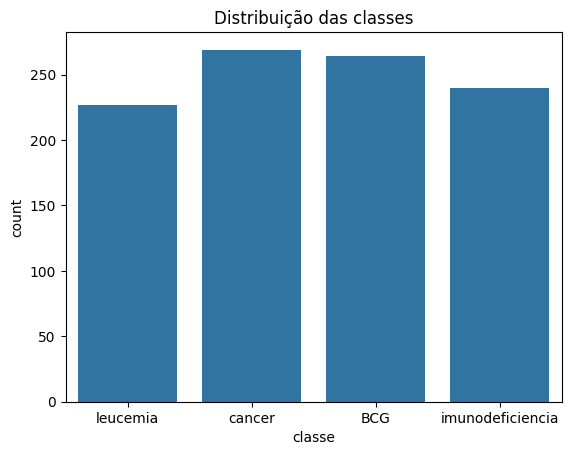

In [12]:
sns.countplot(data=df, x="classe")
plt.title("Distribuição das classes")
plt.show()

In [13]:
# SMOTE (Synthetic Minority Over-sampling Technique)
# -------------------------------------------------
# O que é: técnica de balanceamento que cria observações SINTÉTICAS
#   da classe minoritária (não apenas copia as que já existem).
# Como funciona: para cada paciente da classe minoritária, escolhe um
#   de seus k vizinhos mais próximos (mesma classe) e cria um novo
#   ponto em algum lugar da linha que liga os dois.
# Quando usar: quando uma classe é bem menor que as outras (ex.: 90%
#   x 10%), porque o modelo tende a ignorar a classe rara.
# Cuidado: aplicar SÓ no conjunto de TREINO, depois da divisão.
#   Validação e teste devem continuar com dados reais; senão há
#   vazamento de dados e as métricas ficam otimistas demais.
# Biblioteca: imblearn -> from imblearn.over_sampling import SMOTE
# Neste projeto: NÃO foi necessário, pois as classes já estão
#   balanceadas (razão maior/menor = 1,19; qui-quadrado p = 0,192).
pd.DataFrame({"Pacientes": contagem, "Proporção (%)": proporcao})

,Pacientes,Proporção (%)
classe,,
cancer,269,26.9
BCG,264,26.4
imunodeficiencia,240,24.0
leucemia,227,22.7


✍️ **Comentário 3:** Seguindo o tema de balanceamento da aula 04 (Aquisição dos dados) e o notebook de SMOTE da disciplina, verificou-se se as classes precisariam ser equilibradas. No exemplo da aula, um banco com proporção 90% x 10% foi dividido de forma estratificada e o SMOTE foi aplicado apenas no treino, igualando as classes (630 x 630). No banco de biomarcadores, as quatro classes já estão próximas de 25% cada (de 22,7% a 26,9%), com razão de apenas 1,19 entre a maior e a menor, e o teste qui-quadrado de aderência não rejeita a hipótese de distribuição uniforme (p = 0,192). Portanto, o SMOTE não foi necessário. Da aula, manteve-se a divisão estratificada pela classe, que preserva essas proporções em treino, validação e teste.

✍️ **Comentário 4:** As quatro classes estão bem balanceadas: a mais frequente (cancer, 269 pacientes, 26,9%) tem apenas 1,19 vez o tamanho da menos frequente (leucemia, 227 pacientes, 22,7%), próximo dos 25% esperados para cada uma. O teste qui-quadrado de aderência não rejeita a hipótese de distribuição uniforme entre as classes (p = 0,192). Por isso, não é necessário aplicar SMOTE: essa técnica gera observações sintéticas para compensar classes minoritárias, e aqui nenhuma classe é minoritária. Usá-la sem necessidade adicionaria dados artificiais sem ganho e com risco de sobreajuste. Para manter essas proporções em todas as etapas, a divisão em treino, validação e teste foi feita de forma estratificada pela classe.

In [14]:
# Proporção das classes: divisão estratificada x sorteio simples
import sys
sys.path.append("..")  # permite importar a pasta src a partir de notebooks/
from sklearn.model_selection import train_test_split
from src.dados import estruturar_dados, dividir_dados

df_estr = estruturar_dados(df)

# Estratificada (a usada no projeto)
treino, validacao, teste = dividir_dados(df_estr)

# Sorteio simples, só para comparação
t_s, resto_s = train_test_split(df_estr, test_size=0.30, random_state=42)
v_s, te_s = train_test_split(resto_s, test_size=0.50, random_state=42)

def proporcoes(partes):
    return pd.DataFrame(
        {nome: (d["classe"].value_counts(normalize=True) * 100).round(1)
         for nome, d in partes.items()}
    )

print("Estratificada:")
display(proporcoes({"Banco": df_estr, "Treino": treino, "Validação": validacao, "Teste": teste}))
print("Sorteio simples:")
display(proporcoes({"Treino": t_s, "Validação": v_s, "Teste": te_s}))

Estratificada:


,Banco,Treino,Validação,Teste
classe,,,,
cancer,26.9,26.9,27.3,26.7
BCG,26.4,26.4,26.0,26.7
imunodeficiencia,24.0,24.0,24.0,24.0
leucemia,22.7,22.7,22.7,22.7


Sorteio simples:


,Treino,Validação,Teste
classe,,,
BCG,25.9,25.3,30.0
cancer,28.6,20.7,25.3
imunodeficiencia,23.9,24.0,24.7
leucemia,21.7,30.0,20.0


✍️ **Comentário 5:** A divisão em treino (70%), validação (15%) e teste (15%) foi estratificada pela classe, ou seja, o sorteio foi feito dentro de cada classe para que as três partes mantenham as mesmas proporções do banco completo (ex.: leucemia = 22,7% em todas). Sem estratificação, a validação teria 30,0% de leucemia e o teste 30,0% de BCG, o que distorceria as métricas. Assim, as diferenças de desempenho entre os modelos refletem o próprio modelo, e não um sorteio desigual.

## 4. Medidas resumo e distribuições

In [15]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
CD34,1000.0,0.060034,0.063964,0.000038,0.010408,0.019465,0.112731,0.199757
CD19_1,1000.0,0.243074,0.113677,0.100076,0.146372,0.198089,0.338725,0.498847
CD20_1,1000.0,0.252608,0.120787,0.102262,0.148469,0.198387,0.358607,0.499975
CD22,1000.0,0.252441,0.120602,0.100437,0.150200,0.199057,0.348809,0.499585
CD3_1,964.0,0.296845,0.120873,0.100240,0.187193,0.292676,0.407184,0.498341
CD7,1000.0,0.306717,0.115286,0.101436,0.212423,0.298414,0.401273,0.496797
NMP22,1000.0,5.086000,2.559914,1.000000,3.000000,5.000000,7.000000,9.000000
TP53,1000.0,0.136688,0.069226,0.010049,0.083288,0.149010,0.196692,0.249430
PPD,904.0,41.487249,69.967106,1.011322,4.148214,7.565853,27.341549,248.759379
IFN-γ,1000.0,0.281682,0.160837,0.100193,0.169156,0.232476,0.324549,0.699100


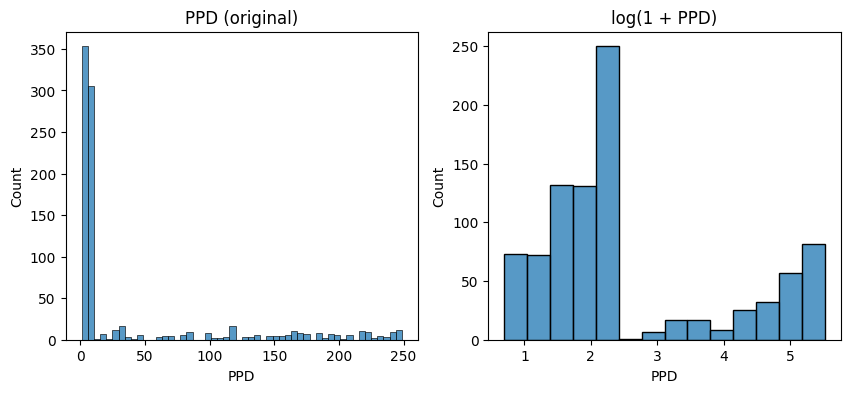

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df["PPD"], ax=ax[0]).set_title("PPD (original)")
sns.histplot(np.log1p(df["PPD"]), ax=ax[1]).set_title("log(1 + PPD)")
plt.show()

In [17]:
# GLOSSÁRIO — breve resuminho do que precisa ser lembrado sobre PPD, BCG, IFN-γ e estatísticas descritivas
# ===========================================
# PPD (Purified Protein Derivative / Derivado Proteico Purificado):
#   proteína extraída do Mycobacterium tuberculosis, usada no teste
#   tuberculínico (prova de Mantoux). Uma reação alta indica que o
#   sistema imune já "conhece" a micobactéria, por infecção ou por
#   vacinação. Neste banco, a coluna PPD é a intensidade dessa resposta.
#
# BCG (Bacilo de Calmette-Guérin): vacina contra a tuberculose, feita
#   com uma cepa atenuada de Mycobacterium bovis. Quem recebeu BCG
#   costuma ter resposta ao PPD mais alta, por isso a classe "BCG"
#   concentra os valores altos de PPD.
#
# IFN-γ (interferon gama): citocina produzida por linfócitos T ativados
#   na resposta a micobactérias; também é mais alto no grupo BCG.
#
# Média: soma dos valores dividida pelo número de pacientes. É
#   sensível a valores extremos.
# Mediana: valor do meio quando os dados são ordenados. Não é afetada
#   por valores extremos. Média muito maior que a mediana indica
#   valores altos "puxando" a média.
# Desvio padrão: o quanto os valores se espalham em torno da média.
#
# Assimetria (skewness / skew): mede o quanto a distribuição pende
#   para um lado. 0 = simétrica; entre 0,5 e 1 = moderada;
#   acima de 1 = forte. Positiva = cauda longa à DIREITA, com
#   poucos valores muito altos.
#
# Distribuição bimodal: tem dois "picos", sinal de duas populações
#   misturadas. Aqui: BCG (PPD entre ~10 e 250) e as demais classes
#   (PPD abaixo de 10).
#
# Transformação log(1 + x) — np.log1p: aplica o logaritmo a (x + 1).
#   Comprime os valores grandes muito mais que os pequenos, reduzindo
#   a assimetria. O "+1" evita erro com x = 0, porque log(0) não existe.
#   Ex.: 9 -> 2,3 | 99 -> 4,6 | 249 -> 5,5
#
# Imputação: preencher valores faltantes com uma estimativa (média ou
#   mediana) em vez de excluir o paciente. Na PPD, a média é calculada
#   já na escala log, para não ser inflada pelos valores do BCG.
#
# Algoritmos baseados em distância (k-NN, K-means, SVM): comparam
#   pacientes pela distância entre seus valores. Uma variável com
#   escala muito grande (como PPD até 249) dominaria essa distância,
#   por isso a transformação log e a padronização são importantes.
# PPD antes e depois da transformação log(1 + x)
ppd = df["PPD"].dropna()
ppd_log = np.log1p(ppd)

resumo = pd.DataFrame(
    {
        "PPD (original)": [ppd.mean(), ppd.median(), ppd.std(), ppd.min(), ppd.max(), ppd.skew()],
        "log(1 + PPD)": [ppd_log.mean(), ppd_log.median(), ppd_log.std(), ppd_log.min(), ppd_log.max(), ppd_log.skew()],
    },
    index=["Média", "Mediana", "Desvio padrão", "Mínimo", "Máximo", "Assimetria (skew)"],
).round(2)

print(f"Média / mediana (original): {ppd.mean() / ppd.median():.1f}")
display(resumo)

# De onde vem a cauda longa? PPD por classe
df.groupby("classe")["PPD"].agg(["mean", "median", "max"]).round(1)

Média / mediana (original): 5.5


,PPD (original),log(1 + PPD)
Média,41.49,2.58
Mediana,7.57,2.15
Desvio padrão,69.97,1.42
Mínimo,1.01,0.70
Máximo,248.76,5.52
Assimetria (skew),1.76,0.94


,mean,median,max
classe,,,
BCG,137.6,146.1,248.8
cancer,5.6,5.7,9.9
imunodeficiencia,5.7,5.4,9.9
leucemia,5.3,5.4,9.9


✍️ **Comentário 6:** A PPD apresenta forte assimetria à direita (skew = 1,76): a média (41,5) é 5,5 vezes maior que a mediana (7,6), com valores de 1,0 a 248,8. A análise por classe mostra que essa cauda vem do grupo BCG (mediana 146,1), enquanto as demais classes ficam abaixo de 10, ou seja, a distribuição é bimodal. A transformação log(1 + PPD) comprimiu a escala (0,7 a 5,5) e reduziu a assimetria para 0,94. Com isso, os valores extremos do BCG deixam de dominar algoritmos baseados em distância (k-NN, K-means, SVM) e a imputação dos 96 faltantes pela média fica menos distorcida, pois é feita na escala log (média 2,58) e não na original (média 41,5, inflada pelo BCG). A separação entre o BCG e as demais classes continua visível e torna a PPD_log uma das variáveis mais informativas para os modelos.

✍️ **Comentário 7:** A análise da PPD justifica a transformação adotada na aula 07 (estruturação), em que a variável foi comparada sob diferentes transformações e a logarítmica foi escolhida. A PPD original é fortemente assimétrica (skew = 1,76; média 41,5 contra mediana 7,6), com cauda longa formada pelo grupo BCG. A transformação log reduz a assimetria para 0,94 e permite preencher os 96 faltantes com a média na escala log, sem a distorção dos valores extremos. No projeto, usou-se np.log1p (log(1 + PPD)) em vez do np.log da aula; como a menor PPD é 1,01, o efeito é praticamente o mesmo, mas o log1p evita erro caso algum valor seja zero.

## 5. Variáveis × classe

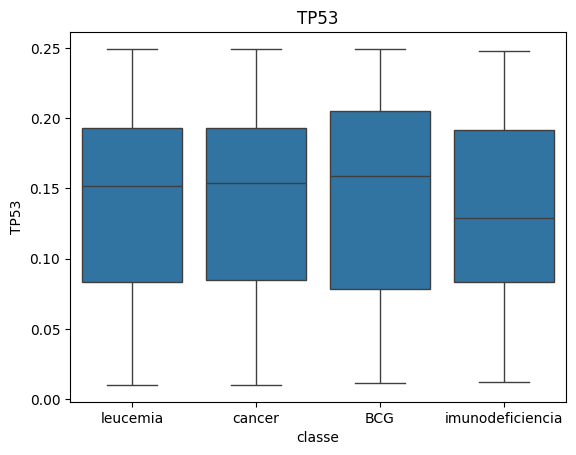

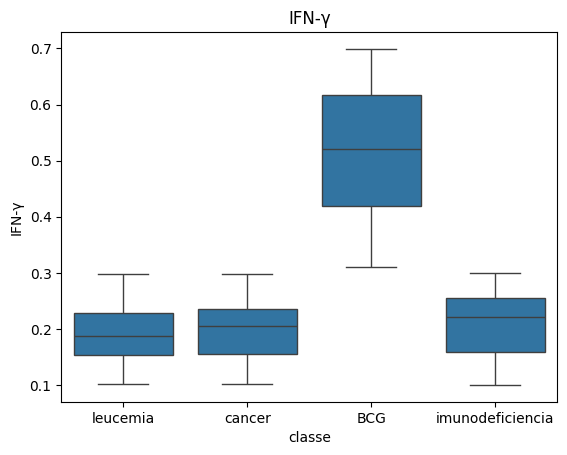

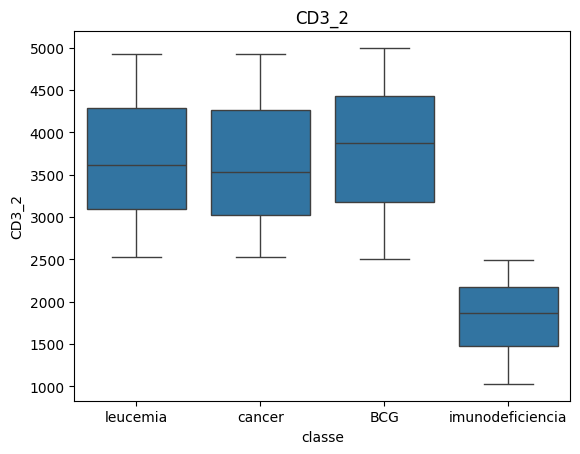

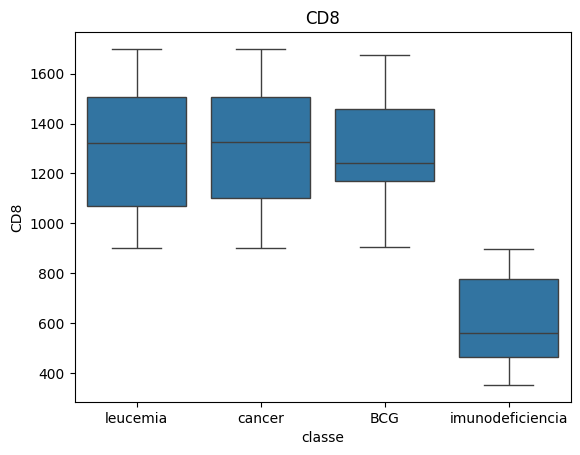

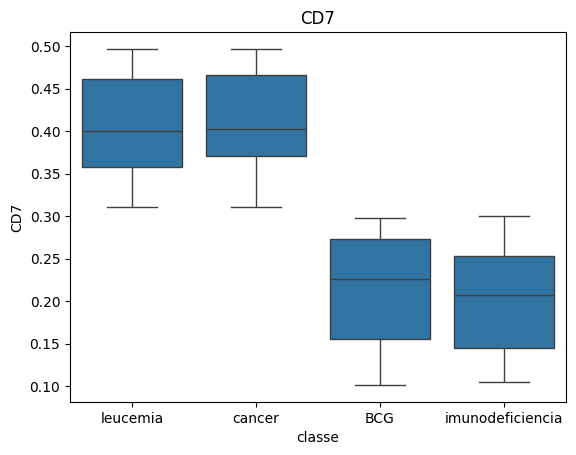

In [18]:
# Boxplot de cada biomarcador por classe.
# O laço "for" repete o gráfico para cada variável da lista.
# Leitura: linha central = mediana; caixa = 50% centrais (Q1 a Q3);
# bigodes = faixa sem outliers; pontos = outliers.
# Caixas em alturas diferentes -> o biomarcador separa as classes.

# POR QUE ESSES BIOMARCADORES?
# São as variáveis numéricas mostrasad na aula 09
# (seleção de variáveis) e usadas nos modelos deste projeto, junto com
# PPD_log e FOXP3. O CD7 representa o bloco de marcadores
# correlacionados entre si (CD34, CD19_1, CD20_1, CD22, CD3_1, CD7;
# no banco da aula ele aparece como "correlatas").
# IFN-γ também é a VARIÁVEL ALVO da regressão, ou seja, o
# valor que o modelo tenta prever.
for var in ["TP53", "IFN-γ", "CD3_2", "CD8", "CD7"]:
    sns.boxplot(data=df, x="classe", y=var)
    plt.title(var)
    plt.show()

In [19]:
# TESTE DE KRUSKAL-WALLIS
# =======================
# O que é: versão NÃO paramétrica da ANOVA. Compara 3 ou mais grupos
#   (aqui, as 4 classes) sem exigir que os dados sigam distribuição
#   normal; trabalha com a ORDEM (posto) dos valores, não com a média.
# Por que usar: vários biomarcadores são assimétricos (ex.: PPD),
#   então a ANOVA tradicional não seria adequada.
# Hipóteses:
#   H0 = o biomarcador tem a mesma distribuição nas 4 classes
#   H1 = pelo menos uma classe difere das outras
#   p < 0,05 -> rejeita H0 -> o biomarcador diferencia as classes.
# Limitação: o teste diz QUE há diferença, mas não ENTRE QUAIS
#   classes. Para isso, olhe as medianas e os boxplots.
# Épsilon² (ε² = H / (n - 1)): tamanho do efeito, de 0 a 1.
#   Como referência: ~0,01 pequeno, ~0,08 médio, ≥ 0,26 grande.
#   Com n grande, quase tudo dá p < 0,05; o ε² mostra se a
#   diferença é grande o suficiente para importar.
# Observação: teste complementar a esta análise, não usado nas aulas.

# Quais biomarcadores separam as classes?
from scipy.stats import chi2_contingency, kruskal

dados = df.copy()
dados["PPD_log"] = np.log1p(dados["PPD"])
variaveis = ["TP53", "IFN-γ", "CD3_2", "CD8", "CD7", "PPD_log"]

# 1. Mediana de cada biomarcador por classe
print("Mediana por classe:")
display(dados.groupby("classe")[variaveis].median().round(3).T)

# 2. Kruskal-Wallis: H0 = o biomarcador tem a mesma distribuição nas 4 classes
#    Épsilon² (0 a 1) = tamanho do efeito: quanto maior, melhor separa as classes
linhas = []
for var in variaveis:
    grupos = [g[var].dropna() for _, g in dados.groupby("classe")]
    h, p = kruskal(*grupos)
    n = sum(len(g) for g in grupos)  # pacientes sem faltante nessa variável
    linhas.append({"Biomarcador": var, "H": h, "p-valor": p, "Épsilon²": h / (n - 1)})
print("Kruskal-Wallis:")
display(pd.DataFrame(linhas).sort_values("Épsilon²", ascending=False).round(4))

# 3. FOXP3 (categórica): proporção por classe + qui-quadrado
_, p_foxp3, _, _ = chi2_contingency(pd.crosstab(dados["FOXP3"], dados["classe"]))
print(f"FOXP3 x classe: qui-quadrado p = {p_foxp3:.2e}")
pd.crosstab(dados["FOXP3"], dados["classe"], normalize="columns").round(2)

Mediana por classe:


classe,BCG,cancer,imunodeficiencia,leucemia
TP53,0.159,0.154,0.129,0.152
IFN-γ,0.521,0.204,0.221,0.187
CD3_2,3874.151,3534.581,1864.706,3612.217
CD8,1243.444,1325.495,561.318,1322.877
CD7,0.226,0.402,0.207,0.400
PPD_log,4.991,1.900,1.849,1.858


Kruskal-Wallis:


,Biomarcador,H,p-valor,Épsilon²
4,CD7,751.3099,0.0000,0.7521
5,PPD_log,537.4036,0.0000,0.5951
1,IFN-γ,592.2590,0.0000,0.5929
2,CD3_2,550.3011,0.0000,0.5509
3,CD8,548.1712,0.0000,0.5487
0,TP53,3.6972,0.2961,0.0037


FOXP3 x classe: qui-quadrado p = 1.80e-216


classe,BCG,cancer,imunodeficiencia,leucemia
FOXP3,,,,
Alterado,0.0,0.0,1.0,0.0
Normal,1.0,1.0,0.0,1.0


In [20]:
# Tabela de contingência FOXP3 x classe.
# normalize="columns": cada coluna (classe) soma 1 -> mostra a
# proporção de FOXP3 Normal/Alterado DENTRO de cada classe,
# o que permite comparar classes de tamanhos diferentes.
pd.crosstab(df["FOXP3"], df["classe"], normalize="columns").round(2)

classe,BCG,cancer,imunodeficiencia,leucemia
FOXP3,,,,
Alterado,0.0,0.0,1.0,0.0
Normal,1.0,1.0,0.0,1.0


✍️ **Comentário 8:** Os boxplots e o teste de Kruskal-Wallis mostram que cinco biomarcadores diferem fortemente entre as classes (p < 0,001), cada um separando um grupo específico. IFN-γ e PPD_log destacam a classe BCG: a mediana de IFN-γ é 0,52, contra cerca de 0,20 nas demais. CD3_2 e CD8 apresentam valores bem mais baixos na imunodeficiência (medianas 1865 e 561, contra cerca de 3500 e 1300 nas outras classes), e a FOXP3 alterada ocorre exclusivamente nesse grupo (100% contra 0%). O CD7 separa cancer e leucemia (mediana ~0,40) de BCG e imunodeficiência (~0,21) e apresenta o maior tamanho de efeito (ε² = 0,75). Já a TP53 não diferencia as classes (p = 0,296). Nenhum biomarcador separa cancer de leucemia, cujos perfis são praticamente idênticos; espera-se, portanto, que os modelos confundam essas duas classes.

## 6. Correlação

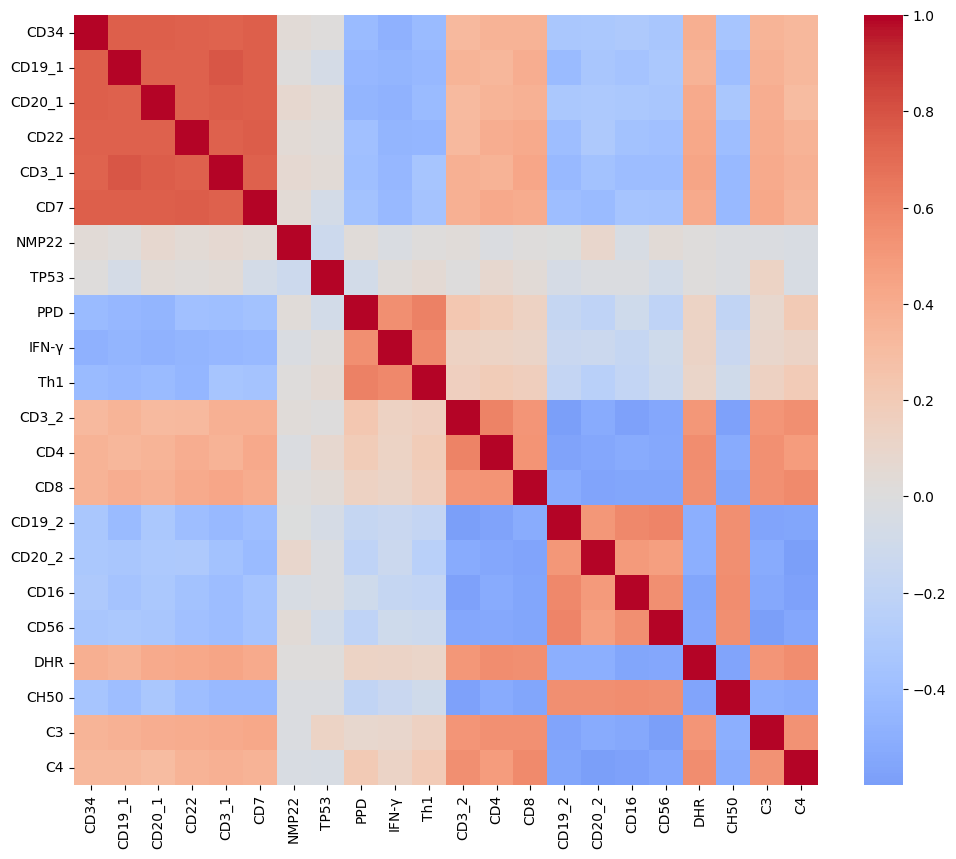

In [21]:
corr = df.select_dtypes("number").corr(method="spearman")
plt.figure(figsize=(12, 10))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.show()

In [22]:
# Bloco de marcadores correlacionados: são redundantes?
from scipy.stats import kruskal

bloco = ["CD34", "CD19_1", "CD20_1", "CD22", "CD3_1", "CD7"]

# 1. Correlação de Spearman dentro do bloco
corr_bloco = dados[bloco].corr(method="spearman")
pares_bloco = corr_bloco.where(np.triu(np.ones(corr_bloco.shape), 1).astype(bool)).stack()
print(f"Correlação entre os pares: de {pares_bloco.min():.2f} a {pares_bloco.max():.2f}")
display(corr_bloco.round(2))

# 2. Quanto cada uma separa as classes (Kruskal-Wallis, épsilon²)
linhas = []
for var in bloco:
    grupos = [g[var].dropna() for _, g in dados.groupby("classe")]
    h, p = kruskal(*grupos)
    n = sum(len(g) for g in grupos)
    linhas.append({"Biomarcador": var, "Épsilon²": h / (n - 1), "Faltantes": dados[var].isna().sum()})
display(pd.DataFrame(linhas).sort_values("Épsilon²", ascending=False).round(3))

# 3. Mediana por classe: todas mostram o mesmo padrão?
dados.groupby("classe")[bloco].median().round(3)

Correlação entre os pares: de 0.73 a 0.78


,CD34,CD19_1,CD20_1,CD22,CD3_1,CD7
CD34,1.00,0.75,0.75,0.74,0.73,0.76
CD19_1,0.75,1.00,0.74,0.74,0.78,0.76
CD20_1,0.75,0.74,1.00,0.74,0.76,0.75
CD22,0.74,0.74,0.74,1.00,0.75,0.76
CD3_1,0.73,0.78,0.76,0.75,1.00,0.74
CD7,0.76,0.76,0.75,0.76,0.74,1.00


,Biomarcador,Épsilon²,Faltantes
4,CD3_1,0.756,36
5,CD7,0.752,0
1,CD19_1,0.751,0
2,CD20_1,0.751,0
3,CD22,0.750,0
0,CD34,0.750,0


,CD34,CD19_1,CD20_1,CD22,CD3_1,CD7
classe,,,,,,
BCG,0.010,0.144,0.148,0.152,0.208,0.226
cancer,0.108,0.349,0.349,0.350,0.408,0.402
imunodeficiencia,0.011,0.150,0.151,0.150,0.163,0.207
leucemia,0.116,0.327,0.362,0.350,0.417,0.400


In [23]:
# Pares muito correlacionados (|r| > 0,7) -> manter só um de cada par
pares = corr.where(np.triu(np.ones(corr.shape), 1).astype(bool)).stack()
pares[pares.abs() > 0.7].sort_values()

CD34    CD3_1     0.733551
CD3_1   CD7       0.737857
CD19_1  CD22      0.739180
CD20_1  CD22      0.741296
CD34    CD22      0.741304
CD19_1  CD20_1    0.743000
CD22    CD3_1     0.749796
CD34    CD20_1    0.750908
CD20_1  CD7       0.751035
CD34    CD19_1    0.752368
CD19_1  CD7       0.755765
CD34    CD7       0.756261
CD20_1  CD3_1     0.757768
CD22    CD7       0.759319
CD19_1  CD3_1     0.782116
dtype: float64

✍️ **Comentário 9:** CD34, CD19_1, CD20_1, CD22, CD3_1 e CD7 formam um bloco fortemente correlacionado (Spearman entre 0,73 e 0,78) e têm o mesmo poder de separação das classes (ε² entre 0,750 e 0,756): todas apresentam valores altos em cancer e leucemia e baixos em BCG e imunodeficiência. Ou seja, carregam essencialmente a mesma informação. Manter todas não acrescentaria informação nova, daria peso excessivo a esse padrão nos algoritmos baseados em distância (k-NN, K-means, SVM) e geraria multicolinearidade nos modelos lineares. Seguindo a aula 07, em que a seleção sequencial (SequentialFeatureSelector com Random Forest) reduziu as variáveis correlacionadas a uma só, manteve-se o CD7, que também não possui valores faltantes. A redução simplifica o modelo e diminui o risco de sobreajuste sem perda de informação.

## 7. Relatório automático (ydata-profiling)

In [24]:
from ydata_profiling import ProfileReport

perfil = ProfileReport(df, title="AED - Biomarcadores", explorative=True)
perfil.to_file("relatorio_aed.html")
# perfil.to_notebook_iframe()  # para ver dentro do notebook

/usr/local/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/tmp/ipykernel_26/1791094670.py:1: DeprecationWarning: 
    `import ydata_profiling` is deprecated and will not receive more updates. 
    Please install fg-data-profiling via `pip install fg-data-profiling` and use `import data_profiling` instead.
    
  from ydata_profiling import ProfileReport
Export report to file: 100%|██████████| 1/1 [00:01<00:00,  1.10s/it]


✍️ **Comentário 10:** Muito pesado para abrir no navegador (não conseguia ver os alertas), por isso optei pelo código abaixo para conseguir ver os alertas e corrigir se necessário.

In [25]:
from ydata_profiling import ProfileReport

# interactions=None: desliga os gráficos de "Interactions" (cada par de
# variáveis cruzado), que deixavam o HTML com ~63 MB e travavam o navegador.
# Com isso o relatório fica com ~2 MB e mantém Overview, Alerts,
# Variables, Correlations, Missing values e Duplicate rows.
perfil = ProfileReport(
    df,
    title="AED - Biomarcadores",
    explorative=True,
    interactions=None,
)
perfil.to_file("relatorio_aed.html")

# Lista dos alertas direto no notebook (mesmo conteúdo da aba Alerts)
for alerta in perfil.get_description().alerts:
    print(alerta)

Export report to file: 100%|██████████| 1/1 [00:00<00:00, 23.01it/s]

[BTA] has a constant value
[hTERT] has a constant value
[uCyt+] has a constant value
[FGFR3] has a constant value
Dataset has 285 (28.5%) duplicate rows
[BCR-ABL] is highly overall correlated with [C3] and 30 other fields
[C3] is highly overall correlated with [BCR-ABL] and 18 other fields
[C4] is highly overall correlated with [BCR-ABL] and 17 other fields
[CD16] is highly overall correlated with [BCR-ABL] and 17 other fields
[CD19_1] is highly overall correlated with [BCR-ABL] and 16 other fields
[CD19_2] is highly overall correlated with [BCR-ABL] and 18 other fields
[CD20_1] is highly overall correlated with [BCR-ABL] and 16 other fields
[CD20_2] is highly overall correlated with [BCR-ABL] and 16 other fields
[CD22] is highly overall correlated with [BCR-ABL] and 16 other fields
[CD34] is highly overall correlated with [BCR-ABL] and 16 other fields
[CD3_1] is highly overall correlated with [BCR-ABL] and 16 other fields
[CD3_2] is highly overall correlated with [BCR-ABL] and 18 othe

✍️ **Comentário 11:** o ydata-profiling gerou 43 alertas de quatro tipos, que confirmam os achados das seções anteriores:

- **Constantes (4):** BTA, hTERT, uCyt+ e FGFR3 têm um único valor e foram removidas, pois não diferenciam os pacientes.
- **Valores faltantes (6):** PPD (9,6%), FGFR3 (5,5%), hTERT (4,6%), BTA (3,9%), uCyt+ (3,7%) e CD3_1 (3,6%). Após a remoção das constantes, restaram apenas PPD e CD3_1, tratadas por imputação.
- **Alta correlação (32):** é o tipo mais frequente e tem duas origens. (1) Redundância entre preditoras: os marcadores CD34, CD19_1, CD20_1, CD22, CD3_1 e CD7, assim como as lógicas TdT, MPO, BCR-ABL e PML-RARA, carregam a mesma informação, as quatro lógicas são idênticas entre si, verdadeiras em 100% dos casos de cancer e leucemia e falsas em 100% de BCG e imunodeficiência. Essa redundância foi tratada mantendo apenas o CD7. (2) Associação com o alvo: a `classe` aparece correlacionada com 30 variáveis, o que é desejável, pois indica que os biomarcadores ajudam a predizê-la.
- **Linhas duplicadas (1):** 285 linhas (28,5%). É o alerta mais relevante para a modelagem, pois pacientes idênticos podem cair ao mesmo tempo no treino e no teste, tornando as métricas otimistas.

Em resumo, os alertas não revelaram problemas novos, mas reforçam as decisões de estruturação (remoção de constantes, imputação, redução de redundância) e chamam atenção para as duplicatas.

✍️ **Comentário 12:** Conclusões Prévias e Possíveis Correções

**Conclusões prévias**

- **Qualidade dos dados:** o banco tem 1000 linhas e 38 variáveis (22 numéricas, 7 lógicas e 9 categóricas). Seis variáveis têm faltantes, que somam 309 células (0,8%) em 260 pacientes; a mais afetada é a PPD (9,6%). Como os faltantes foram inseridos aleatoriamente no banco didático, não há padrão clínico por trás deles. BTA, hTERT, uCyt+ e FGFR3 são constantes e foram removidas; restaram faltantes apenas em PPD e CD3_1, tratadas por imputação (PPD pela média na escala log; CD3_1 pela mediana).
- **Balanceamento:** as quatro classes estão equilibradas (de 22,7% a 26,9%; razão maior/menor = 1,19; qui-quadrado p = 0,192), portanto o SMOTE não foi necessário. A divisão em treino, validação e teste é estratificada pela classe.
- **Transformações:** a PPD é fortemente assimétrica (skew = 1,76) por causa do grupo BCG; o log(1 + PPD) reduziu a assimetria para 0,94 e originou a PPD_log, seguindo a aula 07.
- **Variáveis selecionadas:** TP53, IFN-γ, CD3_2, CD8, PPD_log, CD7 e FOXP3. O CD7 representa o bloco de variáveis correlacionadas (CD34, CD19_1, CD20_1, CD22, CD3_1, CD7 e as lógicas TdT, MPO, BCR-ABL e PML-RARA). IFN-γ e PPD_log destacam o BCG; CD3_2, CD8 e FOXP3 identificam a imunodeficiência; o CD7 separa cancer e leucemia das demais. A TP53 não diferencia as classes (p = 0,296), mas foi mantida por fazer parte da seleção da aula 09.
- **Hipóteses para a modelagem:** espera-se alto acerto para BCG e imunodeficiência, que têm marcadores bem definidos, e confusão entre cancer e leucemia, que não são separadas por nenhum dos biomarcadores selecionados. Na regressão de IFN-γ, espera-se bom desempenho, já que a variável difere fortemente entre as classes.

**Possíveis correções**

- **Linhas duplicadas:** o ydata-profiling apontou 285 linhas duplicadas (28,5%). Se pacientes idênticos aparecerem ao mesmo tempo no treino e no teste, os modelos serão avaliados em pacientes que já viram, e as métricas ficarão otimistas (vazamento de dados). Para seguir a metodologia da disciplina, as 1000 linhas foram mantidas; o tamanho do problema e a alternativa de remoção são analisados na **seção 9** e registrados como possível limitação do projeto.
- **TP53:** como não separa as classes, poderia ser removida em uma versão futura dos modelos, para testar se o desempenho se mantém com menos variáveis.



## 9. Limitação identificada: pacientes duplicados?

O alerta **DUPLICATES** do ydata-profiling (285 linhas, 28,5%) foi investigado em mais detalhe. Esta seção mostra quantos pacientes estão repetidos, por que isso pode ser um problema para a avaliação dos modelos e como o banco ficaria sem as duplicatas. Para seguir a metodologia da disciplina, os modelos usam as 1000 linhas como vieram; as duplicatas são registradas aqui como limitação do projeto.

In [26]:
# 9.1 Quantos pacientes estão repetidos?
# duplicated() marca como True cada linha que é cópia idêntica de uma anterior
copias_extras = df.duplicated().sum()
pacientes_unicos = len(df.drop_duplicates())

# Quantas vezes cada paciente aparece no banco
todas_colunas = list(df.columns)
vezes = df.groupby(todas_colunas, dropna=False).size()
repetidos = (vezes > 1).sum()

print(f"Linhas no banco: {len(df)}")
print(f"Pacientes únicos: {pacientes_unicos}")
print(f"Cópias extras (pandas, df.duplicated): {copias_extras}")
print(f"Pacientes que aparecem mais de uma vez (o '285' do ydata): {repetidos}")

pd.DataFrame(
    {"Pacientes": vezes.value_counts().sort_index()}
).rename_axis("Vezes que aparece no banco")

Linhas no banco: 1000
Pacientes únicos: 400
Cópias extras (pandas, df.duplicated): 600
Pacientes que aparecem mais de uma vez (o '285' do ydata): 285


,Pacientes
Vezes que aparece no banco,
1,115
2,126
3,71
4,42
5,27
6,17
7,1
8,1


✍️ **Comentário 13:** o banco tem 1000 linhas, mas apenas 400 pacientes únicos. Os dois números de duplicatas medem coisas diferentes: o ydata-profiling conta 285 pacientes que aparecem repetidos, enquanto o `df.duplicated()` do pandas conta as 600 cópias extras. Apenas 115 pacientes aparecem uma única vez; os demais aparecem de 2 a 8 vezes. As cópias são idênticas inclusive nos valores faltantes.

In [27]:
# 9.2 Por que isso é um problema? Vazamento entre treino e teste
from sklearn.model_selection import train_test_split

# Divisão 70/15/15 estratificada SEM remover duplicatas (como estava antes)
treino_dup, resto_dup = train_test_split(
    df, test_size=0.30, stratify=df["classe"], random_state=42
)
valid_dup, teste_dup = train_test_split(
    resto_dup, test_size=0.50, stratify=resto_dup["classe"], random_state=42
)


def tem_copia_no_treino(parte, treino):
    # True para cada paciente da 'parte' que tem uma cópia idêntica no treino
    chave = lambda d: d.astype(str).agg("|".join, axis=1)  # noqa: E731
    return chave(parte).isin(set(chave(treino)))


vaz_teste = tem_copia_no_treino(teste_dup, treino_dup).sum()
vaz_valid = tem_copia_no_treino(valid_dup, treino_dup).sum()
print(f"Teste: {vaz_teste} de {len(teste_dup)} pacientes têm cópia idêntica no treino")
print(f"Validação: {vaz_valid} de {len(valid_dup)} pacientes têm cópia idêntica no treino")

Teste: 124 de 150 pacientes têm cópia idêntica no treino
Validação: 115 de 150 pacientes têm cópia idêntica no treino


✍️ **Comentário 14:** sem remover as duplicatas, 124 dos 150 pacientes do teste (83%) e 115 dos 150 da validação têm uma cópia idêntica no treino. Isso é vazamento de dados: o modelo é avaliado em pacientes que ele já viu durante o treino, e as métricas ficam otimistas. Modelos que "decoram" os exemplos, como árvores de decisão e Random Forest, são os mais favorecidos por esse erro.

In [28]:
# 9.3 Como ficaria o banco sem duplicatas? (análise; NÃO adotada nos modelos)
import sys

sys.path.append("..")  # permite importar a pasta src a partir de notebooks/
from scipy.stats import chisquare
from src.dados import dividir_dados, estruturar_dados, remover_duplicatas

# Nomes novos (sufixo _unico) para não sobrescrever variáveis das seções anteriores
df_unico = remover_duplicatas(df)

# Balanceamento
contagem_unico = df_unico["classe"].value_counts()
_, p_unico = chisquare(contagem_unico)
print(f"Pacientes únicos por classe: {contagem_unico.to_dict()}")
print(f"Qui-quadrado de aderência à distribuição uniforme: p = {p_unico:.3f}")

# Divisão que se obteria removendo as duplicatas antes de dividir
treino_unico, validacao_unico, teste_unico = dividir_dados(estruturar_dados(df_unico))
juntos_unico = pd.concat([treino_unico, validacao_unico, teste_unico])
print(
    f"Treino: {len(treino_unico)} | Validação: {len(validacao_unico)} "
    f"| Teste: {len(teste_unico)}"
)
print(f"Pacientes repetidos entre as partes: {juntos_unico.duplicated().sum()}")

# Faltantes depois da remoção
falt_unico = df_unico.isna().sum()
falt_unico = falt_unico[falt_unico > 0].sort_values(ascending=False)
pd.DataFrame(
    {
        "Faltantes": falt_unico,
        "Proporção (%)": (falt_unico / len(df_unico) * 100).round(1),
    }
)

Pacientes únicos por classe: {'leucemia': 100, 'cancer': 100, 'BCG': 100, 'imunodeficiencia': 100}
Qui-quadrado de aderência à distribuição uniforme: p = 1.000
Treino: 280 | Validação: 60 | Teste: 60
Pacientes repetidos entre as partes: 0


,Faltantes,Proporção (%)
PPD,30,7.5
FGFR3,17,4.2
hTERT,14,3.5
BTA,13,3.2
CD3_1,11,2.8
uCyt+,10,2.5


✍️ **Comentário 15:** sem as duplicatas, o banco ficaria com 400 pacientes, exatamente 100 por classe (balanceamento perfeito, qui-quadrado p = 1,000), e a divisão estratificada teria 280 pacientes no treino, 60 na validação e 60 no teste, sem nenhum paciente repetido entre as partes. Os faltantes continuariam nas mesmas seis variáveis (PPD com 7,5%, 30 de 400). Essa alternativa está disponível no código pela função `remover_duplicatas` (`src/dados.py`), mas não foi adotada nos modelos: para seguir a metodologia da disciplina, o `src/pipeline.py` usa as 1000 linhas, com 700 no treino, 150 na validação e 150 no teste.

✍️ **Conclusão final da AED**

- O banco tem 1000 linhas, mas apenas **400 pacientes únicos** (100 por classe): 600 linhas são cópias. Para seguir a metodologia da disciplina, os modelos usam as 1000 linhas como vieram (700 treino, 150 validação, 150 teste).
- **Limitação:** como 124 dos 150 pacientes do teste têm cópia idêntica no treino, as métricas dos modelos devem ser interpretadas como **otimistas**. Modelos que "decoram" exemplos, como árvores de decisão e Random Forest, são os mais favorecidos. Em uma aplicação real, as duplicatas deveriam ser removidas antes da divisão (função `remover_duplicatas`).
- As demais decisões se mantêm: remoção das constantes, transformação log da PPD, redução do bloco correlacionado ao CD7 e as variáveis selecionadas (TP53, IFN-γ, CD3_2, CD8, PPD_log, CD7, FOXP3).
- Hipótese para a modelagem: alto acerto para BCG e imunodeficiência e dificuldade em separar cancer de leucemia, que não se distinguem por nenhum dos biomarcadores selecionados.